# Satellite image classification

AIM : Simple classifier model trained into satellite images for remote sensing,
current focus is purely for exploring tooling with CNN and transfer learning concept, current model might be only usefull into classifying images which it gets to work with, the domain itself contains a variety of problems to solve, such as image filteration, clearance and too advanced image segmentation which we might explore in future notebooks.

About dataset, it contains snapshots of different terrrain llike clouds, desert, green area, water bodies, which could be made together for a classifier to detect terrain information from image. with segmentation and advanced methods nothing can set the limmit.

### Transfer learning hands on with pytorch

Learning for making simple transfer learning based model with torch, taking pretrained model and fine tuning them for our own sparse small dataset, leveraging existing strong model from the pre-trained models.

**Transfer learning objective ( Loss function )**
+ Source domain dataset : $ x_s, x_t $
+ Target Domain dataset : $ x_t, y_t $
+ Neural network para   : $ f_{\theta} $
+ Feature representation: $ \phi(x) $
$$
L_{transfer} = L_{target}( f_{\phi}(x_t), y_t ) + \lambda * R(\phi)
$$

$ L_{target} $ : Loss function on target domain
$ R(\phi) $ : Regularization term for training 
$ \phi $ : Balance parameter between adaptation and preservation

Note : We are currently using predownloaded dataset, we could also build a data loader when building for server which sets up to download dataset from internet to train the model autonomously into the cloude,

In [112]:
# Libraries for deep neural construction
import torch
from torch import nn 

# vision utilities and pretrained models
import torchvision
from torchvision import transforms

# Data handle utilities
import matplotlib.pyplot as plt 
import pandas as pd 
import numpy as np 

# Keeping track of progress
from tqdm.auto import tqdm
from typing import Dict, List, Tuple

# system utilities
import os 
import requests
from pathlib import Path

<Axes: xlabel='label'>

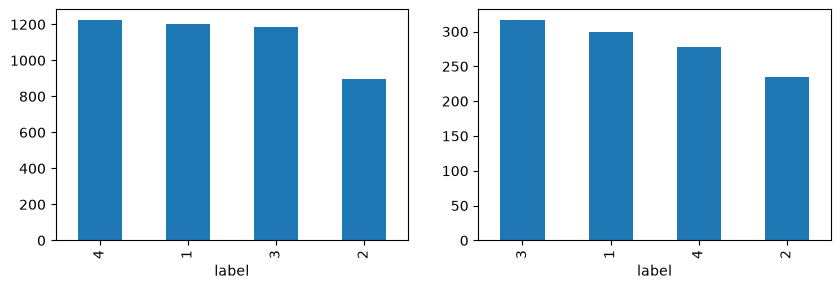

In [113]:
# Data statistics with the annotation file

an_df = pd.read_csv('/home/madhav/workstation/Lab/experiment/data/Satellite-Images/dataset_annotations.csv')

# Foundational statistics about class distribution in dataset
an_df['label'].value_counts() # Dataset is almost balanced with some small sample with desert

mapping = {
    'cloudy':1,
    'desert':2,
    'green_area':3,
    'water':4
}

an_df['label'] = an_df.loc[:, 'label'].map(mapping)

# Train test split with the dataset
from sklearn.model_selection import train_test_split

train, test = train_test_split(an_df, test_size=0.2, random_state=41)

# trian test inspection for distribution
fig, axs = plt.subplots(1,2, figsize=(10,3))

train['label'].value_counts().plot(kind='bar', ax=axs[0])
test['label'].value_counts().plot(kind='bar', ax=axs[1])

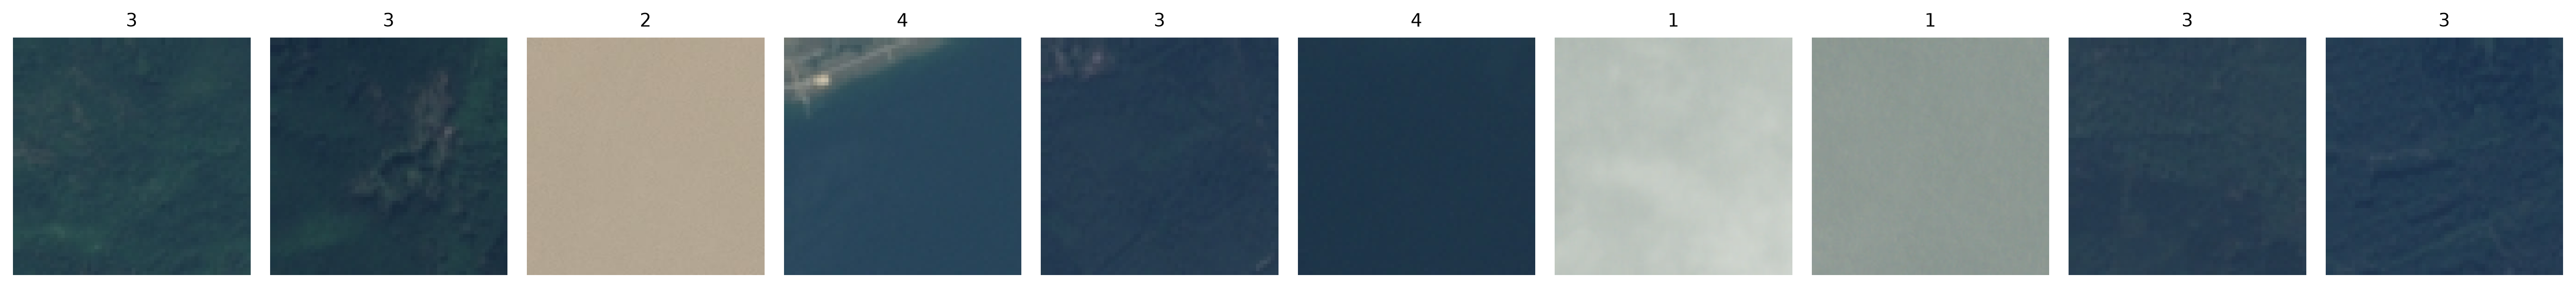

In [114]:
# Random visualization for the images
import random
from PIL import Image
import torch
import matplotlib.pyplot as plt
import pandas as pd

fig, axs = plt.subplots(1, 10, figsize=(20, 4), dpi=300)

sample = train.sample(10)

for i, row in enumerate(sample.itertuples()):
    path = row.image_path
    label = row.label

    image = Image.open(path).convert('RGB')
    
    axs[i].imshow(image)
    axs[i].set_title(label, fontsize=10) 
    axs[i].axis('off')

plt.tight_layout()
plt.show()


In [115]:
# Data preprocessing pipeline
from torchvision import transforms

''' 
creates a standardized transformation pipeline for transfer learning

Aimed for being simple transformation unit for efficient utilization from both source and transfer domain, 
for training the model.

Image net normalization parameter requirements
'''
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Simple pipeline composition with basic edits
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter( # color augmentation !! Might effect the most :)
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# With testing pipeline working for simple early transformation
test_transform = transforms.Compose(
    [
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN, std=IMAGENET_STD
        )
    ]
)

In [116]:
# Data Loader utilities with torch
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import torchvision.io as tv_io
from torchvision.io import ImageReadMode

class ImageDataset(Dataset):
    ''' 
    Simple image dataset object handle,
    Loading dataset through iamges pathways
    ''' 

    def __init__(self, dataframe, transform):
        
        self.image_paths = dataframe['image_path']
        self.labels = dataframe['label']
        self.transform = transform
    
    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths.iloc[idx,]

        image = Image.open(path).convert('RGB')
        print(image)

        transformed_tensor = self.transform(image)
        label = torch.tensor(
            self.labels.iloc[idx,]
        )
                
        return transformed_tensor, label

# Dataset

# NOTE : Label must be set with numerical labling

train_dataset = ImageDataset(train, train_transform)
test_dataset = ImageDataset(test, test_transform)

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=20,
    num_workers=2,
    pin_memory=True
)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=20,
    num_workers=2,
    pin_memory=True
)